# Hierarchical Clustering

## Importing the libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## Importing the dataset

In [3]:
dataset = pd.read_csv('Mall_Customers.csv')

X = dataset.copy()
X["Age_group"] = np.where(X.Age < 18, "0", np.where(X.Age < 25, "1", np.where(X.Age < 30, "2", 
 np.where(X.Age < 35, "3", np.where(X.Age < 40, "4",
 np.where(X.Age < 45, "5", np.where(X.Age < 50, "6", 
 np.where(X.Age < 55, "7", np.where(X.Age < 60, "8", "9")))))))))

X.drop(columns="Age", inplace=True)
X = X.iloc[:, 1:]
X = pd.get_dummies(X, drop_first=True).astype(int)
X

,Annual Income (k$),Spending Score (1-100),Genre_Male,Age_group_2,Age_group_3,Age_group_4,Age_group_5,Age_group_6,Age_group_7,Age_group_8,Age_group_9
0,15,39,1,0,0,0,0,0,0,0,0
1,15,81,1,0,0,0,0,0,0,0,0
2,16,6,0,0,0,0,0,0,0,0,0
3,16,77,0,0,0,0,0,0,0,0,0
4,17,40,0,0,1,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...
195,120,79,0,0,0,1,0,0,0,0,0
196,126,28,0,0,0,0,0,1,0,0,0
197,126,74,1,0,1,0,0,0,0,0,0
198,137,18,1,0,1,0,0,0,0,0,0


## Using the dendrogram to find the optimal number of clusters

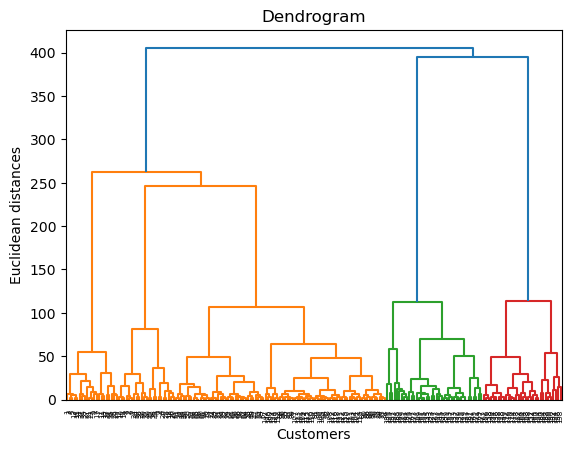

In [11]:
from scipy.cluster import hierarchy as sch

dendrogram = sch.dendrogram(sch.linkage(X, method="ward"))
plt.title('Dendrogram')
plt.xlabel('Customers')
plt.ylabel('Euclidean distances')
plt.show()

## Training the Hierarchical Clustering model on the dataset

In [16]:
from sklearn.cluster import AgglomerativeClustering

hc = AgglomerativeClustering(n_clusters=5, metric="euclidean", linkage="ward")
y_hc = hc.fit_predict(X)
y_hc

array([4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3,
       4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 1,
       4, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 2, 1, 2, 0, 2, 0, 2,
       1, 2, 0, 2, 0, 2, 0, 2, 0, 2, 1, 2, 0, 2, 1, 2, 0, 2, 0, 2, 0, 2,
       0, 2, 0, 2, 0, 2, 1, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2,
       0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2,
       0, 2])

## Createing cluster in dataset

In [17]:
dataset["cluster"] = y_hc
dataset

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,3
2,3,Female,20,16,6,4
3,4,Female,23,16,77,3
4,5,Female,31,17,40,4
...,...,...,...,...,...,...
195,196,Female,35,120,79,2
196,197,Female,45,126,28,0
197,198,Male,32,126,74,2
198,199,Male,32,137,18,0
